In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("../../datasets/a_regression_car_price/car_prices_dataset.csv")
df.head()

,Unnamed: 0,Name,Location,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Mileage,Engine,Power,Seats,New_Price,Price
0,0,Maruti Wagon R LXI CNG,Mumbai,2010,72000,CNG,Manual,First,26.6 km/kg,998 CC,58.16 bhp,5.0,NaN,1.75
1,1,Hyundai Creta 1.6 CRDi SX Option,Pune,2015,41000,Diesel,Manual,First,19.67 kmpl,1582 CC,126.2 bhp,5.0,NaN,12.50
2,2,Honda Jazz V,Chennai,2011,46000,Petrol,Manual,First,18.2 kmpl,1199 CC,88.7 bhp,5.0,8.61 Lakh,4.50
3,3,Maruti Ertiga VDI,Chennai,2012,87000,Diesel,Manual,First,20.77 kmpl,1248 CC,88.76 bhp,7.0,NaN,6.00
4,4,Audi A4 New 2.0 TDI Multitronic,Coimbatore,2013,40670,Diesel,Automatic,Second,15.2 kmpl,1968 CC,140.8 bhp,5.0,NaN,17.74


In [4]:
df.shape

(6019, 14)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6019 entries, 0 to 6018
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Unnamed: 0         6019 non-null   int64  
 1   Name               6019 non-null   str    
 2   Location           6019 non-null   str    
 3   Year               6019 non-null   int64  
 4   Kilometers_Driven  6019 non-null   int64  
 5   Fuel_Type          6019 non-null   str    
 6   Transmission       6019 non-null   str    
 7   Owner_Type         6019 non-null   str    
 8   Mileage            6017 non-null   str    
 9   Engine             5983 non-null   str    
 10  Power              5983 non-null   str    
 11  Seats              5977 non-null   float64
 12  New_Price          824 non-null    str    
 13  Price              6019 non-null   float64
dtypes: float64(2), int64(3), str(9)
memory usage: 658.5 KB


In [6]:
df.isna().sum()

Unnamed: 0              0
Name                    0
Location                0
Year                    0
Kilometers_Driven       0
Fuel_Type               0
Transmission            0
Owner_Type              0
Mileage                 2
Engine                 36
Power                  36
Seats                  42
New_Price            5195
Price                   0
dtype: int64

In [7]:
df.describe()

,Unnamed: 0,Year,Kilometers_Driven,Seats,Price
count,6019.000000,6019.000000,6.019000e+03,5977.000000,6019.000000
mean,3009.000000,2013.358199,5.873838e+04,5.278735,9.479468
std,1737.679967,3.269742,9.126884e+04,0.808840,11.187917
min,0.000000,1998.000000,1.710000e+02,0.000000,0.440000
25%,1504.500000,2011.000000,3.400000e+04,5.000000,3.500000
50%,3009.000000,2014.000000,5.300000e+04,5.000000,5.640000
75%,4513.500000,2016.000000,7.300000e+04,5.000000,9.950000
max,6018.000000,2019.000000,6.500000e+06,10.000000,160.000000


In [9]:
df = df.drop(columns=["Unnamed: 0", "New_Price"])
df.shape

(6019, 12)

In [10]:
df["Brand"] = df["Name"].str.split().str[0]
df = df.drop(columns=["Name"])
df["Brand"].value_counts()

Brand
Maruti           1211
Hyundai          1107
Honda             608
Toyota            411
Mercedes-Benz     318
Volkswagen        315
Ford              300
Mahindra          272
BMW               267
Audi              236
Tata              186
Skoda             173
Renault           145
Chevrolet         121
Nissan             91
Land               60
Jaguar             40
Fiat               28
Mitsubishi         27
Mini               26
Volvo              21
Porsche            18
Jeep               15
Datsun             13
Force               3
ISUZU               2
Smart               1
Ambassador          1
Isuzu               1
Bentley             1
Lamborghini         1
Name: count, dtype: int64

In [11]:
df["Brand"] = df["Brand"].replace({"ISUZU": "Isuzu", "Land": "Land Rover"})
df["Brand"].value_counts()

Brand
Maruti           1211
Hyundai          1107
Honda             608
Toyota            411
Mercedes-Benz     318
Volkswagen        315
Ford              300
Mahindra          272
BMW               267
Audi              236
Tata              186
Skoda             173
Renault           145
Chevrolet         121
Nissan             91
Land Rover         60
Jaguar             40
Fiat               28
Mitsubishi         27
Mini               26
Volvo              21
Porsche            18
Jeep               15
Datsun             13
Isuzu               3
Force               3
Smart               1
Ambassador          1
Bentley             1
Lamborghini         1
Name: count, dtype: int64

In [12]:
df["Brand"].value_counts().tail(8)

Brand
Jeep           15
Datsun         13
Isuzu           3
Force           3
Smart           1
Ambassador      1
Bentley         1
Lamborghini     1
Name: count, dtype: int64

In [13]:
for col in ["Mileage", "Engine", "Power"]:
    df[col] = pd.to_numeric(df[col].str.extract(r"([\d.]+)")[0], errors="coerce")

df[["Mileage", "Engine", "Power"]].describe()

,Mileage,Engine,Power
count,6017.000000,5983.000000,5876.000000
mean,18.134961,1621.276450,113.253050
std,4.582289,601.355233,53.874957
min,0.000000,72.000000,34.200000
25%,15.170000,1198.000000,75.000000
50%,18.150000,1493.000000,97.700000
75%,21.100000,1984.000000,138.100000
max,33.540000,5998.000000,560.000000


In [14]:
df.loc[df["Mileage"] == 0, "Mileage"] = np.nan
df.loc[df["Seats"] == 0, "Seats"] = np.nan
df[["Mileage", "Seats"]].isna().sum()

Mileage    70
Seats      43
dtype: int64

In [15]:
df["Car_Age"] = 2019 - df["Year"]
df = df.drop(columns=["Year"])
df["Car_Age"].describe()

count    6019.000000
mean        5.641801
std         3.269742
min         0.000000
25%         3.000000
50%         5.000000
75%         8.000000
max        21.000000
Name: Car_Age, dtype: float64

In [16]:
df["Kilometers_Driven"].sort_values(ascending=False).head(10)

2328    6500000
340      775000
1860     720000
358      620000
2823     480000
3092     480000
4491     445000
3649     300000
1528     299322
1975     282000
Name: Kilometers_Driven, dtype: int64

In [17]:
df = df[df["Kilometers_Driven"] < 600000]
df.shape

(6015, 12)

In [18]:
df.duplicated().sum()

np.int64(2)

In [19]:
df = df.drop_duplicates()
df.shape

(6013, 12)

In [20]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["Price"])
y = df["Price"]

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=42)

print(X_train.shape, X_val.shape, X_test.shape)

(4209, 11) (902, 11) (902, 11)


In [21]:
num_cols = ["Kilometers_Driven", "Mileage", "Engine", "Power", "Seats", "Car_Age"]
cat_cols = ["Location", "Fuel_Type", "Transmission", "Owner_Type", "Brand"]
print(len(num_cols), len(cat_cols))

6 5


In [22]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

In [23]:
num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", drop="first")),
])
preprocessor = ColumnTransformer([
    ("num", num_pipe, num_cols),
    ("cat", cat_pipe, cat_cols),
])

In [24]:
X_train_p = preprocessor.fit_transform(X_train)
X_val_p = preprocessor.transform(X_val)
X_test_p = preprocessor.transform(X_test)
print(X_train_p.shape, X_val_p.shape, X_test_p.shape)

(4209, 51) (902, 51) (902, 51)


c:\Users\3B\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [4] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


In [25]:
set(X_val["Brand"]) - set(X_train["Brand"])

set()

In [26]:
for col in cat_cols:
    print(col, "| val:", set(X_val[col]) - set(X_train[col]), "| test:", set(X_test[col]) - set(X_train[col]))

Location | val: set() | test: set()
Fuel_Type | val: set() | test: set()
Transmission | val: set() | test: set()
Owner_Type | val: set() | test: set()
Brand | val: set() | test: {'Ambassador', 'Bentley'}


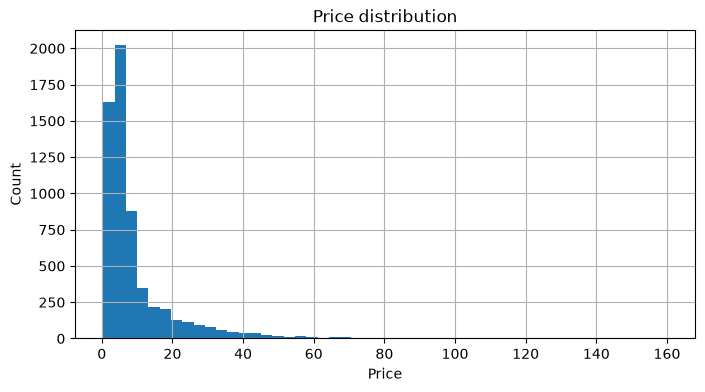

In [27]:
import matplotlib.pyplot as plt

df["Price"].hist(bins=50, figsize=(8, 4))
plt.title("Price distribution")
plt.xlabel("Price")
plt.ylabel("Count")
plt.show()

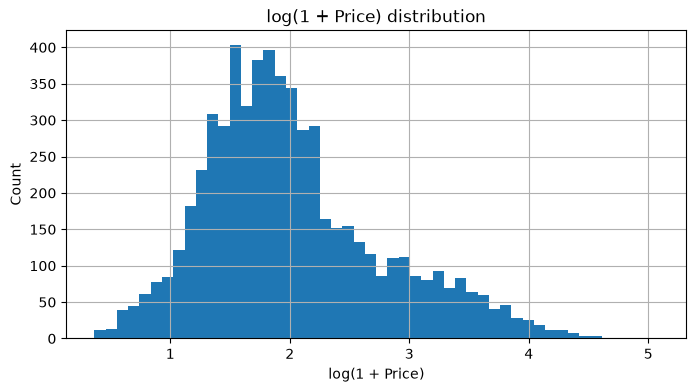

In [28]:
df["Price_log"] = np.log1p(df["Price"])
df["Price_log"].hist(bins=50, figsize=(8, 4))
plt.title("log(1 + Price) distribution")
plt.xlabel("log(1 + Price)")
plt.ylabel("Count")
plt.show()

In [29]:
y_train_log = np.log1p(y_train)
y_val_log = np.log1p(y_val)
y_test_log = np.log1p(y_test)